# Zomato: Rating & Customer Engagement Analysis

**Question:** What is associated with higher ratings and more customer engagement (votes) for restaurants on Zomato?

**Data:** Zomato_Restaurant_Dataset.xlsx, 9,550 restaurants, 21 columns. Rating = `Aggregate rating`; engagement = `Votes`.

**Analyses:**
1. Table booking and online delivery vs rating and votes
2. Price range / cost vs rating
3. Vote outliers and "hidden gems" (highly rated, few votes)
4. The same questions in SQL (SQLite) as a cross-check

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

df = pd.read_excel("Zomato_Restaurant_Dataset.xlsx")
print(df.shape)
df.info()
df.head(10)

(9550, 21)
<class 'pandas.DataFrame'>
RangeIndex: 9550 entries, 0 to 9549
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Restaurant ID         9550 non-null   int64  
 1   Restaurant Name       9550 non-null   object 
 2   Country Code          9550 non-null   int64  
 3   City                  9550 non-null   str    
 4   Address               9550 non-null   str    
 5   Locality              9550 non-null   str    
 6   Locality Verbose      9550 non-null   str    
 7   Longitude             9550 non-null   float64
 8   Latitude              9550 non-null   float64
 9   Cuisines              9541 non-null   str    
 10  Average Cost for two  9550 non-null   int64  
 11  Currency              9550 non-null   str    
 12  Has Table booking     9550 non-null   str    
 13  Has Online delivery   9550 non-null   str    
 14  Is delivering now     9550 non-null   str    
 15  Switch to order menu 

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229
5,18189371,Din Tai Fung,162,Mandaluyong City,"Ground Floor, Mega Fashion Hall, SM Megamall, ...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056314,14.583764,Chinese,...,Botswana Pula(P),No,No,No,No,3,4.4,Green,Very Good,336
6,6300781,Buffet 101,162,Pasay City,"Building K, SM By The Bay, Sunset Boulevard, M...","SM by the Bay, Mall of Asia Complex, Pasay City","SM by the Bay, Mall of Asia Complex, Pasay Cit...",120.979667,14.531333,"Asian, European",...,Botswana Pula(P),Yes,No,No,No,4,4.0,Green,Very Good,520
7,6301290,Vikings,162,Pasay City,"Building B, By The Bay, Seaside Boulevard, Mal...","SM by the Bay, Mall of Asia Complex, Pasay City","SM by the Bay, Mall of Asia Complex, Pasay Cit...",120.979333,14.540000,"Seafood, Filipino, Asian, European",...,Botswana Pula(P),Yes,No,No,No,4,4.2,Green,Very Good,677
8,6300010,Spiral - Sofitel Philippine Plaza Manila,162,Pasay City,"Plaza Level, Sofitel Philippine Plaza Manila, ...","Sofitel Philippine Plaza Manila, Pasay City","Sofitel Philippine Plaza Manila, Pasay City, P...",120.980090,14.552990,"European, Asian, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.9,Dark Green,Excellent,621
9,6314987,Locavore,162,Pasig City,"Brixton Technology Center, 10 Brixton Street, ...",Kapitolyo,"Kapitolyo, Pasig City",121.056532,14.572041,Filipino,...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,532


## Data cleaning

- Fixed garbled city names (Brasília, São Paulo, İstanbul).
- Rebuilt `Currency` from `Country Code`. The raw column was wrong (e.g. Manila restaurants listed in Botswana Pula).
- 2,148 restaurants have a rating of 0 ("Not rated"). They are excluded from all rating and vote analysis, leaving **7,402 rated restaurants**.
- Some restaurant names are still garbled. They are flagged in `name_garbled` and do not affect the analysis.

In [2]:
city_fix = {
    "Bras\ufffd_lia": "Brasília",
    "S\ufffd\ufffdo Paulo": "São Paulo",
    "\ufffd\ufffdstanbul": "İstanbul",
}
df["City"] = df["City"].replace(city_fix)
print(df["City"].str.contains("\ufffd").sum())

0


In [3]:
currency_fix = {
    1: "INR", 14: "AUD", 30: "BRL", 37: "CAD", 94: "IDR", 148: "NZD",
    162: "PHP", 166: "QAR", 184: "SGD", 189: "ZAR", 191: "LKR",
    208: "TRY", 214: "AED", 215: "GBP", 216: "USD",
}
df["Currency"] = df["Country Code"].map(currency_fix)

In [4]:
df["name_garbled"] = df["Restaurant Name"].str.contains("\ufffd")

In [5]:
print((df["Aggregate rating"] == 0).sum())
print(df["Currency"].nunique())
print(df["Rating text"].value_counts())

2148
15
Rating text
Average      3737
Not rated    2148
Good         2100
Very Good    1078
Excellent     301
Poor          186
Name: count, dtype: int64


In [6]:
df = df.rename(columns={
    "Aggregate rating": "rating",
    "Average Cost for two": "cost",
    "Price range": "price_range",
    "Has Table booking": "table_booking",
    "Has Online delivery": "online_delivery",
    "Votes": "votes",
})
rated = df[df["rating"] > 0].copy()
print(len(rated))

7402


## 1. Table booking and online delivery vs rating and votes

Mann-Whitney U tests are used because ratings and votes are not normally distributed.

In [7]:
for col in ["table_booking", "online_delivery"]:
    print(rated.groupby(col).agg(
        n=("rating", "size"),
        mean_rating=("rating", "mean"),
        mean_votes=("votes", "mean"),
        median_votes=("votes", "median"),
    ).round(3))
    yes = rated[rated[col] == "Yes"]
    no = rated[rated[col] == "No"]
    print(stats.mannwhitneyu(yes["rating"], no["rating"]).pvalue)
    print(stats.mannwhitneyu(yes["votes"], no["votes"]).pvalue)

                  n  mean_rating  mean_votes  median_votes
table_booking                                             
No             6291        3.414     172.839          49.0
Yes            1111        3.588     368.004         165.0
1.4501327814567427e-27
3.1707967148851273e-96
                    n  mean_rating  mean_votes  median_votes
online_delivery                                             
No               5047        3.467     193.862          47.0
Yes              2355        3.381     219.858          84.0
0.0008978218507445171
5.1674911584765773e-39


In [8]:
print(pd.crosstab(rated["price_range"], rated["table_booking"], normalize="index").round(3))
print(rated.groupby(["price_range", "table_booking"])["rating"].agg(["mean", "count"]).round(3))

table_booking     No    Yes
price_range                
1              1.000  0.000
2              0.919  0.081
3              0.546  0.454
4              0.537  0.463
                            mean  count
price_range table_booking              
1           No             3.239   2743
            Yes            3.700      1
2           No             3.378   2490
            Yes            3.370    220
3           No             3.912    749
            Yes            3.616    624
4           No             4.054    309
            Yes            3.701    266


**Finding:** Restaurants with table booking rate higher on average (3.59 vs 3.41) and get far more votes (median 165 vs 49). Online delivery shows the opposite on rating (3.38 vs 3.47) but still has more votes (median 84 vs 47).

**But price range changes the picture.** Table booking is almost absent in price range 1 and common in tiers 3 and 4. Within the tiers, booking restaurants do not rate higher: in tier 2 the means are equal (3.37 vs 3.38), and in tiers 3 and 4 they rate *lower* (3.62 vs 3.91, 3.70 vs 4.05). The overall booking advantage mostly reflects booking restaurants being more expensive, not booking itself.

## 2. Price range and cost vs rating

`price_range` is ordinal, so Spearman is the primary measure (Pearson shown for comparison). Cost is compared only within India, because `Average Cost for two` is in local currency, and is log-transformed because it is right-skewed.

In [9]:
print(stats.spearmanr(rated["price_range"], rated["rating"]))
print(stats.pearsonr(rated["price_range"], rated["rating"]))

india = rated[(rated["Country Code"] == 1) & (rated["cost"] > 0)].copy()
india["log_cost"] = np.log10(india["cost"])
print(stats.spearmanr(india["cost"], india["rating"]))
print(stats.pearsonr(india["log_cost"], india["rating"]))

SignificanceResult(statistic=np.float64(0.40173881789168103), pvalue=np.float64(3.368093015734153e-285))
PearsonRResult(statistic=np.float64(0.4031926731392148), pvalue=np.float64(1.913714028161178e-287))
SignificanceResult(statistic=np.float64(0.33233770559671794), pvalue=np.float64(1.6933842600822167e-167))
PearsonRResult(statistic=np.float64(0.32175490506444676), pvalue=np.float64(1.5381944839664183e-156))


**Finding:** Price range has a moderate positive correlation with rating (Spearman ≈ 0.40). Within India, cost shows a weaker positive relationship (Spearman ≈ 0.33). Higher-priced restaurants tend to rate higher, but this is correlation, not proof that price drives rating.

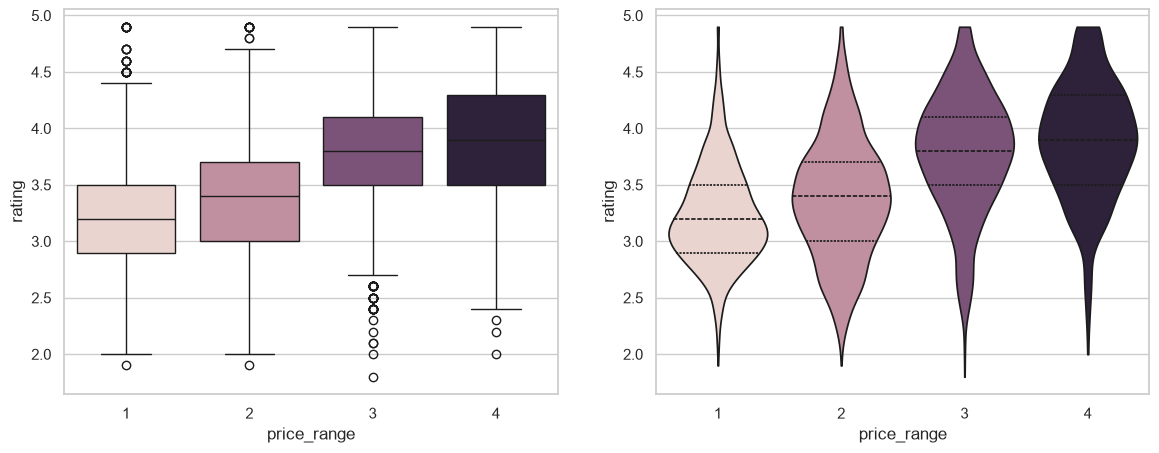

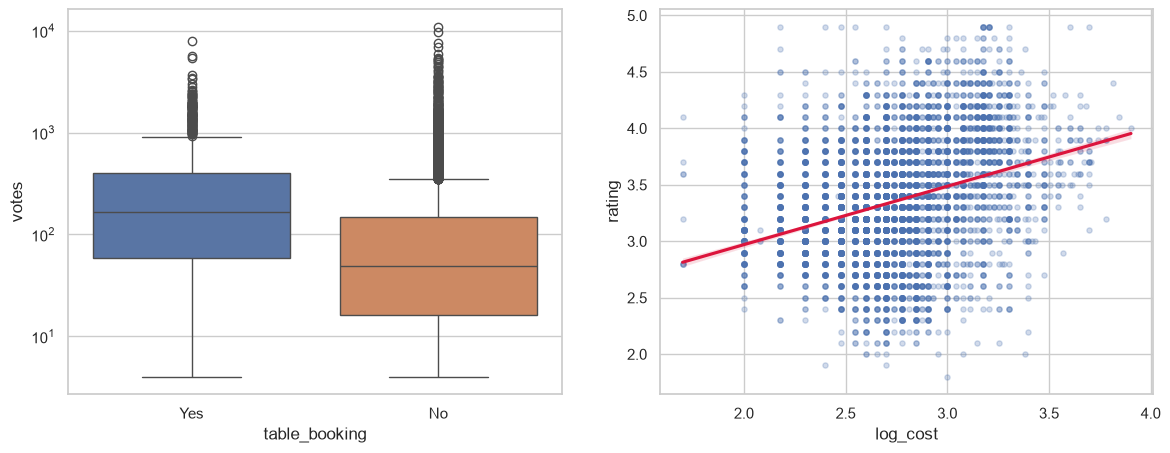

In [10]:
sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=rated, x="price_range", y="rating", hue="price_range", legend=False, ax=axes[0])
sns.violinplot(data=rated, x="price_range", y="rating", hue="price_range", inner="quartile", cut=0, legend=False, ax=axes[1])
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=rated, x="table_booking", y="votes", hue="table_booking", legend=False, ax=axes[0])
axes[0].set_yscale("log")
sns.regplot(data=india, x="log_cost", y="rating", scatter_kws={"alpha": 0.25, "s": 14}, line_kws={"color": "crimson"}, ax=axes[1])
plt.show()

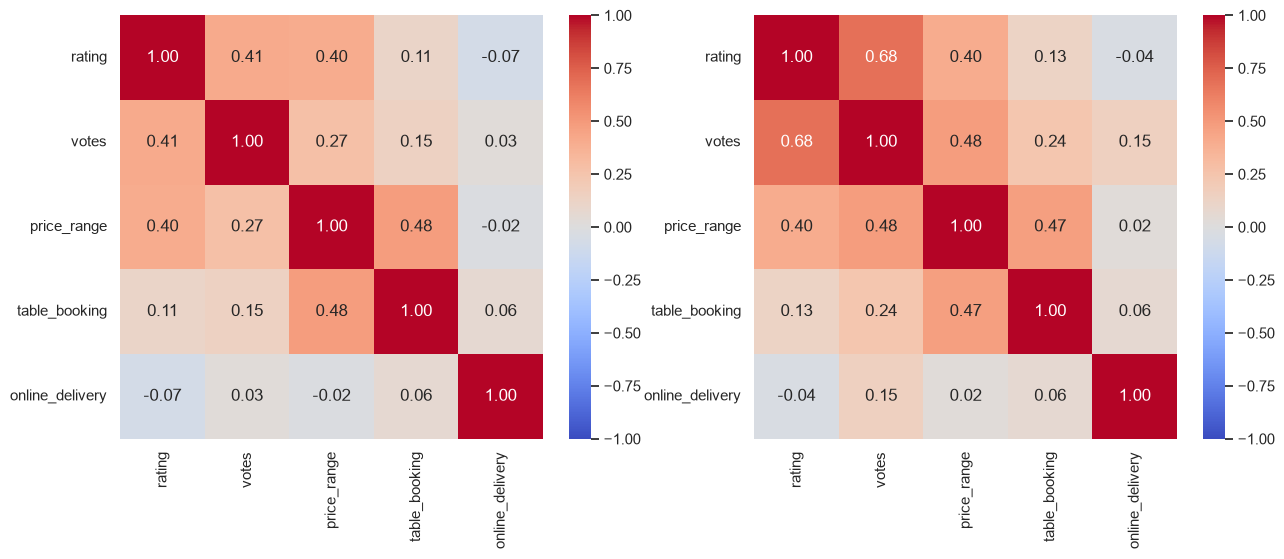

In [11]:
num = rated.assign(
    table_booking=(rated["table_booking"] == "Yes").astype(int),
    online_delivery=(rated["online_delivery"] == "Yes").astype(int),
)[["rating", "votes", "price_range", "table_booking", "online_delivery"]]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.heatmap(num.corr(method="pearson"), annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=axes[0])
sns.heatmap(num.corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=axes[1])
plt.show()

**Reading the plots:** The boxplots and violins show how rating is distributed within each price range. Votes are plotted on a log scale because a few restaurants have thousands of votes. The heatmaps show Pearson and Spearman correlations side by side so you can check that the conclusions don't depend on the method.

## 3. Vote outliers and hidden gems

- **Outliers:** votes above Q3 + 1.5×IQR (424 votes). 838 restaurants (about 11%) are flagged. Votes are heavily right-skewed, so these are high-engagement restaurants, not errors, and they are kept.
- **Hidden gems:** rating ≥ 4.0 and votes ≤ the median (60). This gives 109 restaurants.

In [12]:
q1, median_votes, q3 = rated["votes"].quantile([0.25, 0.5, 0.75])
upper_fence = q3 + 1.5 * (q3 - q1)
rated["vote_outlier"] = rated["votes"] > upper_fence

top_voted = rated.nlargest(10, "votes")[["Restaurant Name", "City", "votes", "rating"]]

hidden_gems = rated[(rated["rating"] >= 4.0) & (rated["votes"] <= median_votes)]
hidden_gems = hidden_gems.sort_values(["rating", "votes"], ascending=[False, True])
print(upper_fence, rated["vote_outlier"].sum(), len(hidden_gems))

424.0 838 109


## 4. SQL cross-check (SQLite)

The cleaned data is loaded into SQLite and the main results are reproduced with `GROUP BY`, `CASE WHEN`, `HAVING` and a window-function median. The numbers match the Python results (e.g. table booking 3.414 vs 3.588 average rating; median votes 60; 109 hidden gems).

In [13]:
import sqlite3
import pandas as pd

con = sqlite3.connect("zomato.db")

In [14]:
raw = pd.read_excel("Zomato_Restaurant_Dataset.xlsx")

city_fix = {
    "Bras\ufffd_lia": "Brasília",
    "S\ufffd\ufffdo Paulo": "São Paulo",
    "\ufffd\ufffdstanbul": "İstanbul",
}
currency_fix = {
    1: "INR", 14: "AUD", 30: "BRL", 37: "CAD", 94: "IDR", 148: "NZD",
    162: "PHP", 166: "QAR", 184: "SGD", 189: "ZAR", 191: "LKR",
    208: "TRY", 214: "AED", 215: "GBP", 216: "USD",
}

sql_df = raw.copy()
sql_df["City"] = sql_df["City"].replace(city_fix)
sql_df["Currency"] = sql_df["Country Code"].map(currency_fix)
sql_df.columns = [c.replace(" ", "_") for c in sql_df.columns]
sql_df.to_sql("zomato", con, index=False, if_exists="replace")

9550

In [15]:
def run(query):
    return pd.read_sql(query, con)

In [16]:
run("SELECT COUNT(*) AS total_rows, SUM(Aggregate_rating = 0) AS unrated FROM zomato")

,total_rows,unrated
0,9550,2148


In [17]:
run("PRAGMA table_info(zomato)")["name"].tolist()

['Restaurant_ID',
 'Restaurant_Name',
 'Country_Code',
 'City',
 'Address',
 'Locality',
 'Locality_Verbose',
 'Longitude',
 'Latitude',
 'Cuisines',
 'Average_Cost_for_two',
 'Currency',
 'Has_Table_booking',
 'Has_Online_delivery',
 'Is_delivering_now',
 'Switch_to_order_menu',
 'Price_range',
 'Aggregate_rating',
 'Rating_color',
 'Rating_text',
 'Votes']

In [18]:
run("SELECT COUNT(*) AS bad_city FROM zomato WHERE City LIKE '%' || char(65533) || '%'")

,bad_city
0,0


In [19]:
run("""
SELECT Has_Table_booking,
       COUNT(*) AS restaurants,
       ROUND(AVG(Aggregate_rating), 3) AS avg_rating,
       ROUND(AVG(Votes), 1) AS avg_votes
FROM zomato
WHERE Aggregate_rating > 0
GROUP BY Has_Table_booking
""")

,Has_Table_booking,restaurants,avg_rating,avg_votes
0,No,6291,3.414,172.8
1,Yes,1111,3.588,368.0


In [20]:
run("""
SELECT Has_Table_booking, Has_Online_delivery,
       COUNT(*) AS restaurants,
       ROUND(AVG(Aggregate_rating), 3) AS avg_rating,
       ROUND(AVG(Votes), 1) AS avg_votes
FROM zomato
WHERE Aggregate_rating > 0
GROUP BY Has_Table_booking, Has_Online_delivery
HAVING COUNT(*) > 100
ORDER BY avg_rating DESC
""")

,Has_Table_booking,Has_Online_delivery,restaurants,avg_rating,avg_votes
0,Yes,Yes,433,3.612,476.5
1,Yes,No,678,3.572,298.7
2,No,No,4369,3.451,177.6
3,No,Yes,1922,3.329,162.0


In [21]:
run("""
SELECT Price_range, Has_Table_booking,
       COUNT(*) AS n,
       ROUND(AVG(Aggregate_rating), 3) AS avg_rating
FROM zomato
WHERE Aggregate_rating > 0
GROUP BY Price_range, Has_Table_booking
HAVING COUNT(*) > 30
ORDER BY Price_range, Has_Table_booking
""")

,Price_range,Has_Table_booking,n,avg_rating
0,1,No,2743,3.239
1,2,No,2490,3.378
2,2,Yes,220,3.370
3,3,No,749,3.912
4,3,Yes,624,3.616
5,4,No,309,4.054
6,4,Yes,266,3.701


In [22]:
run("""
SELECT CASE WHEN Aggregate_rating >= 4.5 THEN 'Excellent'
            WHEN Aggregate_rating >= 4.0 THEN 'Very Good'
            WHEN Aggregate_rating >= 3.5 THEN 'Good'
            WHEN Aggregate_rating >= 2.5 THEN 'Average'
            ELSE 'Poor' END AS rating_band,
       COUNT(*) AS restaurants,
       ROUND(AVG(Votes), 1) AS avg_votes,
       ROUND(100.0 * SUM(CASE WHEN Has_Table_booking = 'Yes' THEN 1 ELSE 0 END) / COUNT(*), 1) AS pct_table_booking
FROM zomato
WHERE Aggregate_rating > 0
GROUP BY rating_band
ORDER BY MIN(Aggregate_rating) DESC
""")

,rating_band,restaurants,avg_votes,pct_table_booking
0,Excellent,301,851.8,15.0
1,Very Good,1078,520.4,22.4
2,Good,2100,229.4,19.3
3,Average,3737,48.2,10.5
4,Poor,186,90.7,12.9


**Finding:** Engagement rises sharply with rating band: average votes go from 48 (Average) to 852 (Excellent). "Excellent" restaurants are not the ones with the most table booking (15%, vs 22% for Very Good).

In [23]:
run("""
SELECT Restaurant_Name, City, Votes, Aggregate_rating, Price_range
FROM zomato
ORDER BY Votes DESC
LIMIT 10
""")

,Restaurant_Name,City,Votes,Aggregate_rating,Price_range
0,Toit,Bangalore,10934,4.8,4
1,Truffles,Bangalore,9667,4.7,2
2,Hauz Khas Social,New Delhi,7931,4.3,3
3,Peter Cat,Kolkata,7574,4.3,3
4,AB's - Absolute Barbecues,Bangalore,6907,4.6,3
5,Barbeque Nation,Kolkata,5966,4.9,3
6,Big Brewsky,Bangalore,5705,4.5,3
7,AB's - Absolute Barbecues,Hyderabad,5434,4.9,3
8,The Black Pearl,Bangalore,5385,4.1,3
9,BarBQ,Kolkata,5288,4.2,2


In [24]:
run("""
WITH ranked AS (
  SELECT Votes,
         ROW_NUMBER() OVER (ORDER BY Votes) AS rn,
         COUNT(*) OVER () AS total
  FROM zomato
  WHERE Aggregate_rating > 0
)
SELECT AVG(Votes) AS median_votes
FROM ranked
WHERE rn IN ((total + 1) / 2, (total + 2) / 2)
""")

,median_votes
0,60.0


In [25]:
run("""
SELECT Restaurant_Name, City, Aggregate_rating, Votes, Price_range
FROM zomato
WHERE Aggregate_rating >= 4.0 AND Votes <= 60
ORDER BY Aggregate_rating DESC, Votes ASC
""")

,Restaurant_Name,City,Aggregate_rating,Votes,Price_range
0,Coco Bambu,Brasília,4.9,30,4
1,Braseiro da G��vea,Rio de Janeiro,4.9,40,4
2,Garota de Ipanema,Rio de Janeiro,4.9,49,4
3,The Great Indian Pub,Dehradun,4.9,50,4
4,TT Burger,Rio de Janeiro,4.8,19,3
...,...,...,...,...,...
104,Royal Dine - Hotel Royal Cliff,Kanpur,4.0,54,4
105,Cravity,New Delhi,4.0,55,1
106,Hearken Caf��,New Delhi,4.0,55,2
107,Starbucks,Noida,4.0,59,2


In [26]:
run("""
SELECT City, COUNT(*) AS hidden_gems
FROM zomato
WHERE Aggregate_rating >= 4.0 AND Votes <= 60
GROUP BY City
HAVING COUNT(*) >= 5
ORDER BY hidden_gems DESC
""")

,City,hidden_gems
0,New Delhi,30
1,Rio de Janeiro,19
2,São Paulo,11
3,Gurgaon,11
4,Brasília,5


**Finding:** New Delhi (30), Rio de Janeiro (19), São Paulo (11) and Gurgaon (11) have the most hidden gems. These are raw counts and are not adjusted for how many restaurants each city has, so large cities rank high partly by size.

In [27]:
con.close()

## Key Findings

**Scope:** 9,550 restaurants in the dataset. 2,148 were unrated (rating = 0) and excluded, leaving 7,402 for analysis.

1. **Table booking looks beneficial but isn't.** Restaurants with booking average 3.59 vs 3.41 without, and get about 3x the median votes (165 vs 49). But booking is concentrated in expensive restaurants (about 45% of Price range 3 and 4, almost none in range 1). Within the same price range, booking restaurants rate lower: 3.62 vs 3.91 in range 3, and 3.70 vs 4.05 in range 4. After controlling for price range, booking is associated with about -0.21 rating points.

2. **Online delivery has essentially no effect on ratings.** Delivery restaurants average 3.38 vs 3.47 without. After controlling for price range, the gap shrinks to about -0.04 points, and the correlation is near zero. Delivery does go with somewhat higher vote counts (median 84 vs 47).

3. **Higher price range goes with higher ratings, with diminishing returns.** Average rating rises from 3.24 (range 1) to 3.38, 3.78 and 3.89 (range 4). Spearman correlation is 0.40. In India, cost vs rating gives Spearman 0.33. The jump from range 3 to 4 is only about 0.1.

4. **Votes and ratings are strongly linked.** Spearman correlation is 0.68, the strongest relationship in the data. Votes are heavily skewed: median 60, mean 202, with 838 restaurants above the outlier fence of 424 votes. Ratings from very few voters are also less reliable.

5. **Hidden gems.** 109 restaurants are rated 4.0 or higher with 60 or fewer votes (the median). New Delhi has the most (30), followed by Rio de Janeiro (19).

## Data Cleaning
- Excluded 2,148 unrated restaurants (rating 0 means "Not rated", not a bad rating).
- Fixed 3 corrupted city names (São Paulo, Brasília, İstanbul) using country codes.
- Rebuilt the currency column from country codes (e.g. Philippines was labelled "Botswana Pula").
- Excluded zero-cost rows from cost analysis. Cost was analysed for India only, since costs are in 12 currencies.
- Some restaurant names remain garbled in the source file and can't be recovered.


## Conclusions

1. Table booking and delivery look related to ratings and votes overall, but the booking-rating link disappears once price range is controlled for.
2. Higher price range is moderately associated with higher ratings.
3. Higher-rated restaurants get many more votes, and a small group of restaurants dominates total votes.
4. Hidden gems exist across cities, concentrated in the largest ones.

## Limitations
- Correlation is not causation: pricier restaurants may attract different reviewers.
- Hidden gems are candidates, not proven winners. A 4.9 from 30 voters is a noisy estimate.
- The dataset is about 90% India, so global conclusions lean on Indian restaurants.